# Single-phase NILM, stage 1: event detection → steady-state features → Random Forest

Pipeline: **aggregate power → steady-state change detector → differential features from
steady windows (transition excluded) → appliance-event classifier → evaluation against sub-meters.**

### Decisions (short)
| Decision | Choice | Why |
|---|---|---|
| Dataset | **REDD low_freq**, houses 1–3 | 1 Hz whole-home mains + per-circuit sub-meters (≈3 s), so every aggregate event can be labelled automatically. Downloadable here via a public GitHub mirror; the official REDD, UK-DALE, iAWE, BLUED, PLAID hosts are blocked from this sandbox. 1 Hz real-power steps are also what an ESP32 + CT board can deliver first. |
| Aggregate | mains1 + mains2 | REDD homes are US split-phase; the sum is the whole-home signal, equivalent to one Pakistani single-phase feed. |
| Detector | steady-state segmentation (Hart 1992 style) | Simplest credible method; parameters are physical (W, s) and portable to the ESP32. |
| Ground truth | the same detector run on each sub-meter (7 s window) | Gives labelled ON/OFF/step events with ΔP for every metered appliance. |
| Split | **chronological** per house: first 70 % of valid data = train, last 30 % = test, 10 min buffer | No event from the test period is seen during training or detector tuning. |
| Classifier | Random Forest, `class_weight="balanced"`, 300 trees | Plan's first choice; handles unscaled mixed features; compared with kNN and a majority baseline. |
| Normalisation | none | REDD low_freq has no voltage channel, so 230 V normalisation is not possible here (needed later on our own hardware). Trees do not need feature scaling; kNN uses a train-fitted StandardScaler. |

In [1]:
import sys, json, subprocess
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
from nilm.data import download_redd, load_house
from nilm.events import DetectorParams, detect_events, check_windows_exclude_transition
from nilm.synthetic import make_synthetic
from nilm.groundtruth import GT_PARAMS, ground_truth_events, match_events, detection_scores
from nilm.features import event_features, STEADY_FEATURES, TRANSIENT_FEATURES, ALL_FEATURES
from nilm.pipeline import run_house, cross_house, split_time, tune_detector
from nilm.report import synthetic_check, save_all, summary_tables
from nilm import plots
OUT = ROOT / "results"; PLOTS = OUT / "plots"; PLOTS.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 160); pd.set_option("display.precision", 3)
download_redd((1, 2, 3))   # no-op when the files are already present

PosixPath('/home/user/FYP/data/redd')

## 1. Detector verification on a synthetic signal with known transitions

{
 "n_true": 10,
 "n_detected": 10,
 "true_found": 10,
 "false_events": 0,
 "max_abs_delta_error_w": 3.43404169334417,
 "events_whose_windows_touch_true_transition": 0,
 "pre_before_transition": true,
 "post_after_transition": true,
 "windows_well_formed": true,
 "n_events": 10
}


,true_idx,true_delta_p,true_trans_len,true_name,det_idx,det_delta_p,det_trans_start,det_trans_end,det_pre_start,det_pre_end,det_post_start,det_post_end
0,100,150,0,fridge ON,100,152.176,100,99,95,99,100,104
1,220,1500,2,kettle ON,220,1501.371,220,221,215,219,222,226
2,300,-1500,1,kettle OFF,300,-1500.081,300,300,295,299,301,305
3,420,60,0,lamp ON,420,61.799,420,419,415,419,420,424
4,600,1100,2,microwave ON,600,1102.627,600,601,595,599,602,606
5,780,-1100,0,microwave OFF,780,-1103.434,780,779,775,779,780,784
6,900,-150,1,fridge OFF,900,-148.829,900,900,895,899,901,905
7,1200,40,0,small ON,1200,38.658,1200,1199,1195,1199,1200,1204
8,1400,-60,0,lamp OFF,1400,-60.948,1400,1399,1395,1399,1400,1404
9,1500,-40,0,small OFF,1500,-40.384,1500,1499,1495,1499,1500,1504


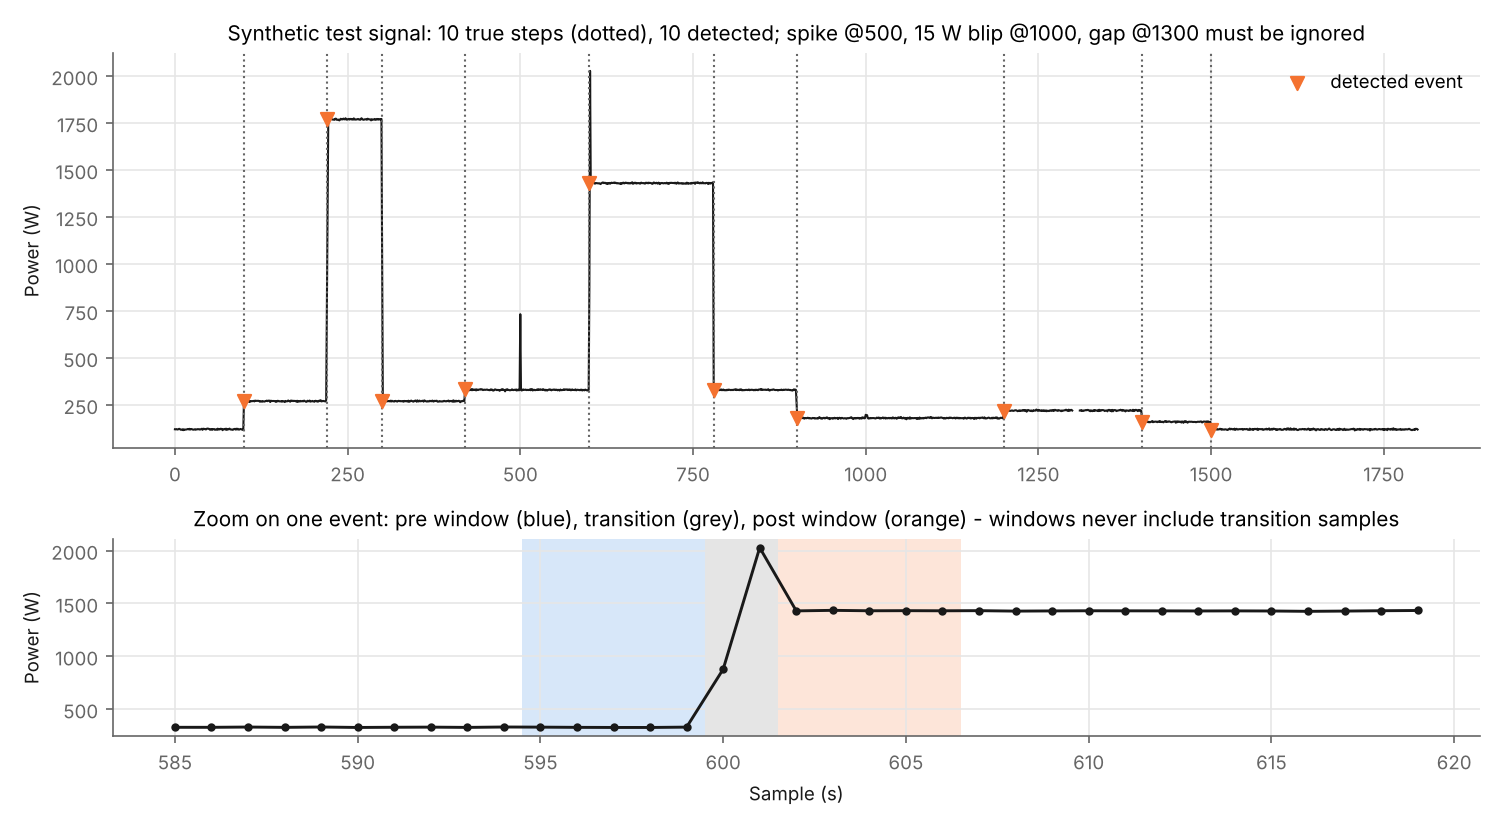

In [2]:
synth, p_syn, truth, ev_syn = synthetic_check(PLOTS)
print(json.dumps(synth, indent=1))
display(pd.concat([truth[["idx", "delta_p", "trans_len", "name"]].add_prefix("true_"),
                   ev_syn[["idx", "delta_p", "trans_start", "trans_end", "pre_start", "pre_end", "post_start", "post_end"]]
                   .add_prefix("det_")], axis=1))
assert synth["true_found"] == synth["n_true"] and synth["false_events"] == 0
assert synth["events_whose_windows_touch_true_transition"] == 0
display(Image(PLOTS / "synthetic_detector.png"))

In [3]:
# unit tests (5 seeds, spikes, gaps, thresholds)
r = subprocess.run([sys.executable, "-m", "pytest", "-q", str(ROOT / "tests")], capture_output=True, text=True, cwd=ROOT)
print(r.stdout[-400:])

.............                                                            [100%]
13 passed in 0.21s



## 2. Load REDD house 1 and check the data

In [4]:
agg, subs, rep = load_house(1)
print(json.dumps(rep, indent=1))
t = agg.index.to_numpy()
assert np.all(np.diff(t) == 1), "grid must be uniform 1 s"
print("aggregate shape", agg.shape, "| sub-meter shape", subs.shape)
print("NaN fraction per sub-meter column where aggregate is valid:")
print(subs[agg.notna()].isna().mean().round(4).to_dict())
print("sub-meter negative values:", int((subs < 0).sum().sum()))
v = agg.notna() & subs.notna().all(axis=1)
print(f"share of aggregate energy explained by sub-meters: {subs[v].sum(axis=1).sum() / agg[v].sum():.1%}")

{
 "house": 1,
 "mains_channels": [
  1,
  2
 ],
 "n_raw_mains_samples": 1561660,
 "grid_seconds": 3134094,
 "valid_agg_seconds": 1576475,
 "agg_nan_fraction": 0.49699179411976796,
 "start_utc": "2011-04-18 13:22:09",
 "end_utc": "2011-05-24 19:57:02",
 "n_gaps_over_60s": 21,
 "labels": [
  "bathroom_gfi",
  "dishwasher",
  "electric_heat",
  "kitchen_outlets",
  "lighting",
  "microwave",
  "oven",
  "refrigerator",
  "stove",
  "washer_dryer"
 ],
 "sub_nan_fraction_when_agg_valid": 0.0006064162133874626,
 "agg_min_w": 90.81,
 "agg_max_w": 12332.8,
 "agg_negative_samples": 0
}
aggregate shape (3134094,) | sub-meter shape (3134094, 10)
NaN fraction per sub-meter column where aggregate is valid:
{'oven': 0.0006, 'refrigerator': 0.0006, 'dishwasher': 0.0006, 'kitchen_outlets': 0.0006, 'lighting': 0.0006, 'washer_dryer': 0.0006, 'microwave': 0.0006, 'bathroom_gfi': 0.0006, 'electric_heat': 0.0006, 'stove': 0.0006}
sub-meter negative values: 0


share of aggregate energy explained by sub-meters: 76.0%


In [5]:
day = agg.loc[t[0] + 86400 * 2: t[0] + 86400 * 3]
fig, ax = plt.subplots(figsize=(11, 3))
ax.plot(pd.to_datetime(day.index, unit="s"), day.to_numpy(), lw=0.6, color="#191919")
ax.set(title="House 1 aggregate, one day (UTC)", ylabel="W"); fig.tight_layout(); plt.show()

## 3. Ground-truth events from sub-meters, chronological split, detector tuning (train only)

In [6]:
gt = ground_truth_events(subs, GT_PARAMS, valid=agg.notna())
print(len(gt), "ground-truth events (|ΔP| >= 30 W, only where the aggregate exists)")
print(gt.appliance.value_counts().to_dict())
t_split = split_time(agg, 0.7)
print("split at", pd.to_datetime(t_split, unit="s"), "UTC (70 % of valid seconds before it)")
best, tuning = tune_detector(agg, gt, t_split, buffer_s=600)
print("chosen detector params (train period only):", best)
display(tuning.head(6))

3592 ground-truth events (|ΔP| >= 30 W, only where the aggregate exists)
{'refrigerator': 1209, 'microwave': 643, 'washer_dryer': 614, 'dishwasher': 468, 'kitchen_outlets': 291, 'lighting': 232, 'oven': 74, 'bathroom_gfi': 61}
split at 2011-05-03 08:00:37 UTC (70 % of valid seconds before it)


chosen detector params (train period only): DetectorParams(window=5, tol_abs=10.0, tol_rel=0.01, min_delta=30.0, feat_len=5, max_transition=30)


,window,tol_abs,tol_rel,min_delta,feat_len,max_transition,tp,fp,fn,precision,recall,f1
0,5,10.0,0.01,30.0,5,30,1994,313,599,0.864,0.769,0.814
1,5,20.0,0.01,30.0,5,30,1993,321,600,0.861,0.769,0.812
2,5,10.0,0.02,30.0,5,30,1971,306,622,0.866,0.760,0.809
3,5,20.0,0.02,30.0,5,30,1964,308,629,0.864,0.757,0.807
4,3,5.0,0.01,30.0,5,30,2071,476,522,0.813,0.799,0.806
5,5,5.0,0.04,30.0,5,30,1946,293,647,0.869,0.750,0.805


## 4–7. Full pipeline for houses 1–3 (detect → match → features → split → RF → evaluate)

In [7]:
results = {h: run_house(h, data=(agg, subs, rep) if h == 1 else None) for h in (1, 2, 3)}
cross = cross_house(results, train_house=1)
det, cls, e2e = save_all(results, cross, synth, OUT)
r1 = results[1]
assert r1["params"] == best

### 4. Event detection (aggregate events vs sub-meter events, ±10 s, same sign, similar size)

,house,split,tp,fp,fn,n_gt,precision,recall,f1
0,1,train,1994,313,599,2593,0.864,0.769,0.814
1,1,test,788,73,210,998,0.915,0.790,0.848
2,2,train,1634,527,308,1942,0.756,0.841,0.796
3,2,test,633,112,116,749,0.850,0.845,0.847
4,3,train,3022,486,812,3834,0.861,0.788,0.823
5,3,test,1276,250,543,1819,0.836,0.701,0.763


House 1 test recall per appliance:


,recall,n_gt
appliance,,
bathroom_gfi,1.000,16
dishwasher,0.874,143
kitchen_outlets,0.797,64
lighting,0.908,65
microwave,0.778,176
oven,0.895,19
refrigerator,0.883,358
washer_dryer,0.427,157


steady windows exclude the transition on real data: {'pre_before_transition': True, 'post_after_transition': True, 'windows_well_formed': True, 'n_events': 3169}
timing offset det - sub-meter (s) percentiles 5/50/95: [-6. -1.  1.]


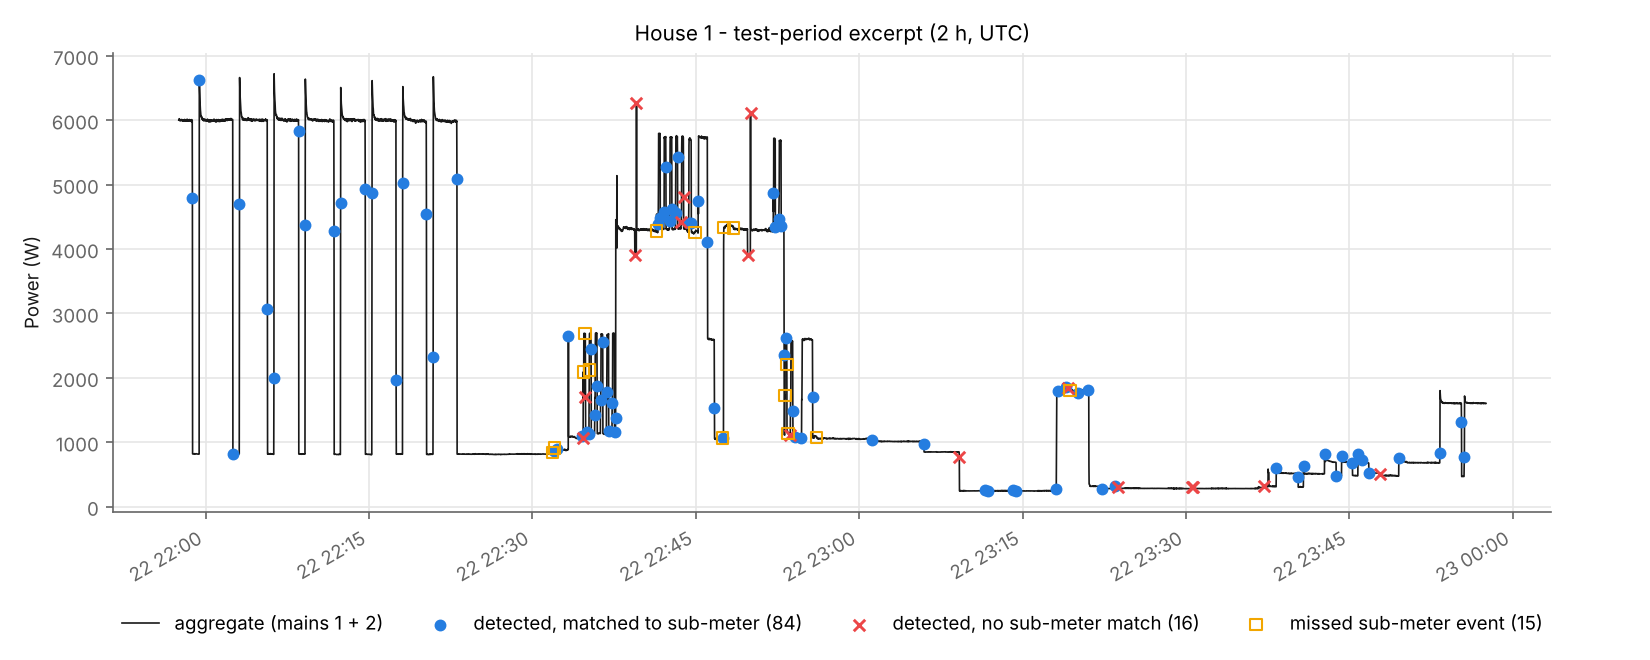

In [8]:
display(det)
print("House 1 test recall per appliance:"); display(r1["per_app_recall"])
print("steady windows exclude the transition on real data:", r1["windows_check"])
ev1 = r1["events"]; m = ev1[ev1.gt_dt.notna()]
print("timing offset det - sub-meter (s) percentiles 5/50/95:", np.percentile(m.gt_dt, [5, 50, 95]))
display(Image(PLOTS / "house1_test_excerpt.png"))

### 5. Feature checks

NaN: 0 | inf: 0


,count,mean,std,min,25%,50%,75%,max
delta_p,3169.0,9.274,1667.337,-8754.830,-177.940,-31.730,216.960,5964.230
abs_delta_p,3169.0,883.685,1413.843,30.040,56.980,208.740,1436.780,8754.830
delta_std,3169.0,0.763,4.226,-22.117,-0.724,0.220,1.882,32.437
rel_delta_std,3169.0,0.002,0.022,-0.422,-0.002,0.001,0.006,0.152
trans_len,3169.0,2.701,3.496,0.000,1.000,1.000,3.000,28.000
overshoot_ratio,3169.0,0.942,2.769,0.000,0.000,0.000,0.077,42.617


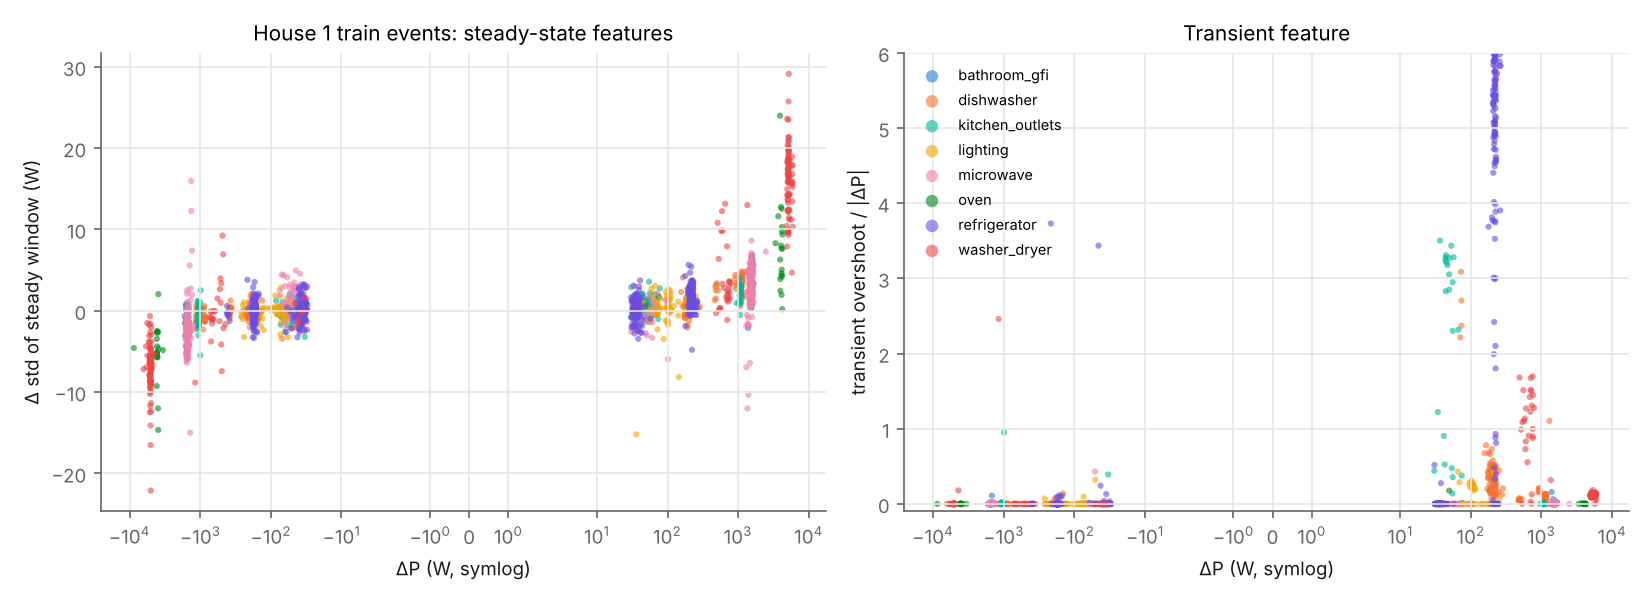

In [9]:
f = ev1[ALL_FEATURES]
print("NaN:", int(f.isna().sum().sum()), "| inf:", int(np.isinf(f.to_numpy()).sum()))
display(f.describe().T)
display(Image(PLOTS / "house1_feature_space.png"))

### 6. Classification (test period only), class balance

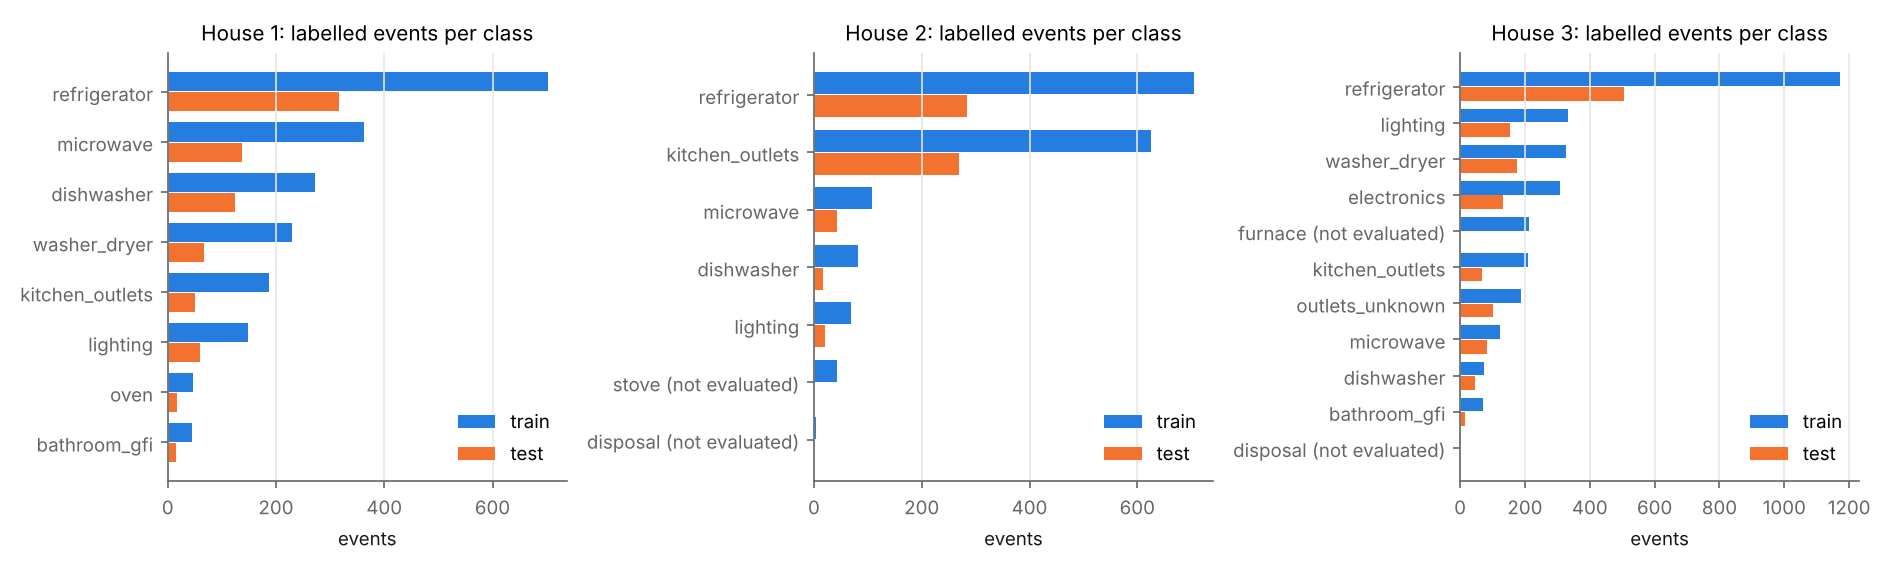

House 1 - classes not evaluable (<20 train or <5 test events): none
House 2 - classes not evaluable (<20 train or <5 test events): {'disposal': {'train': 4, 'test': 0}, 'stove': {'train': 42, 'test': 0}}
House 3 - classes not evaluable (<20 train or <5 test events): {'disposal': {'train': 3, 'test': 0}, 'furnace': {'train': 213, 'test': 0}}


,house,model,accuracy,macro_f1,weighted_f1
0,1,RF steady+transient,0.834,0.767,0.836
1,1,RF steady-state only,0.782,0.681,0.785
2,1,kNN (k=5) steady-state,0.744,0.658,0.737
3,1,Majority class,0.401,0.072,0.230
4,2,RF steady+transient,0.959,0.902,0.960
5,2,RF steady-state only,0.923,0.814,0.928
6,2,kNN (k=5) steady-state,0.945,0.779,0.939
7,2,Majority class,0.449,0.124,0.278
8,3,RF steady+transient,0.802,0.707,0.805
9,3,RF steady-state only,0.699,0.606,0.709


,house,end_to_end_recall,n_test_events_classified,classes_evaluated,classes_not_evaluated
0,1,0.658,788,8,-
1,2,0.810,633,5,"disposal (4/0), stove (42/0)"
2,3,0.563,1276,9,"disposal (3/0), furnace (213/0)"


                 precision    recall  f1-score   support

   bathroom_gfi       0.54      0.88      0.67        16
     dishwasher       0.83      0.76      0.79       125
kitchen_outlets       0.60      0.75      0.67        51
       lighting       0.62      0.66      0.64        59
      microwave       0.88      0.84      0.86       137
           oven       0.71      0.59      0.65        17
   refrigerator       0.91      0.89      0.90       316
   washer_dryer       0.94      0.99      0.96        67

       accuracy                           0.83       788
      macro avg       0.76      0.79      0.77       788
   weighted avg       0.84      0.83      0.84       788



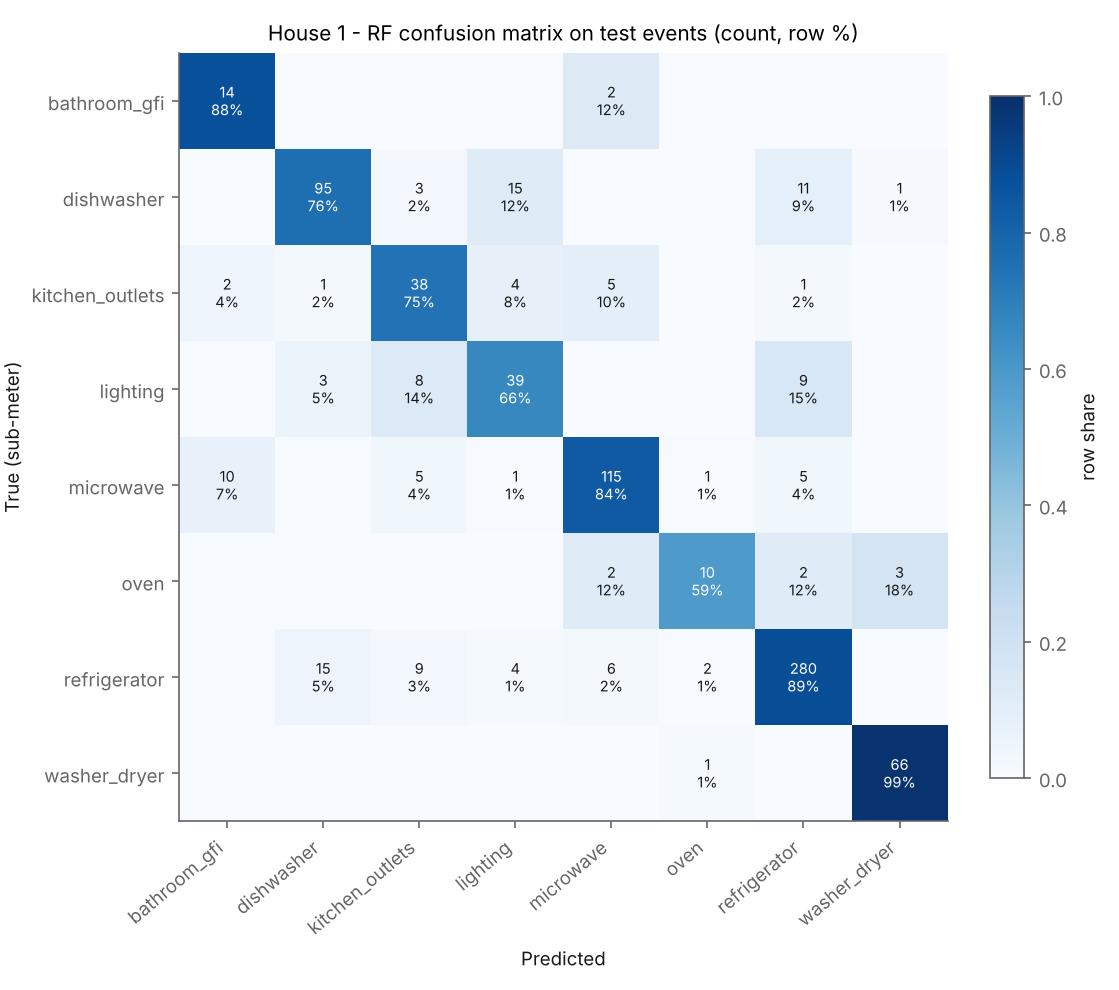

RF feature importance (house 1):


abs_delta_p        0.392
delta_p            0.252
delta_std          0.105
overshoot_ratio    0.096
rel_delta_std      0.085
trans_len          0.071
dtype: float64

RF predictions for test detections with NO sub-meter match (not scored):
{'refrigerator': 29, 'microwave': 15, 'kitchen_outlets': 9, 'washer_dryer': 7, 'lighting': 5, 'dishwasher': 4, 'oven': 2, 'bathroom_gfi': 2}


In [10]:
display(Image(PLOTS / "class_balance.png"))
for h, r in results.items():
    print(f"House {h} - classes not evaluable (<20 train or <5 test events):",
          r["not_evaluable"].to_dict(orient="index") or "none")
display(cls)
display(e2e)
print(r1["report_txt"])
display(Image(PLOTS / "house1_confusion.png"))
print("RF feature importance (house 1):"); display(r1["feature_importance"].round(3))
print("RF predictions for test detections with NO sub-meter match (not scored):")
print(r1["unmatched_test_predictions"].to_dict())

House 2
                 precision    recall  f1-score   support

     dishwasher       0.83      0.94      0.88        16
kitchen_outlets       0.99      1.00      0.99       270
       lighting       0.78      0.90      0.84        20
      microwave       0.78      0.91      0.84        43
   refrigerator       0.98      0.94      0.96       284

       accuracy                           0.96       633
      macro avg       0.87      0.94      0.90       633
   weighted avg       0.96      0.96      0.96       633

House 3
                 precision    recall  f1-score   support

   bathroom_gfi       0.52      0.87      0.65        15
     dishwasher       0.33      0.33      0.33        45
    electronics       0.82      0.73      0.77       133
kitchen_outlets       0.67      0.62      0.65        66
       lighting       0.57      0.68      0.62       154
      microwave       0.87      0.80      0.83        83
outlets_unknown       0.59      0.64      0.61       102
   refriger

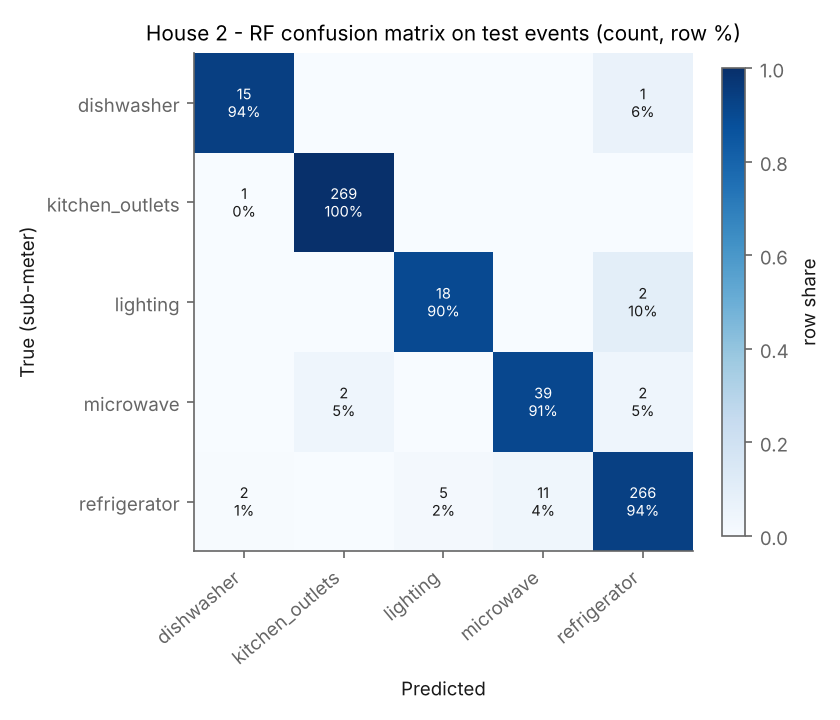

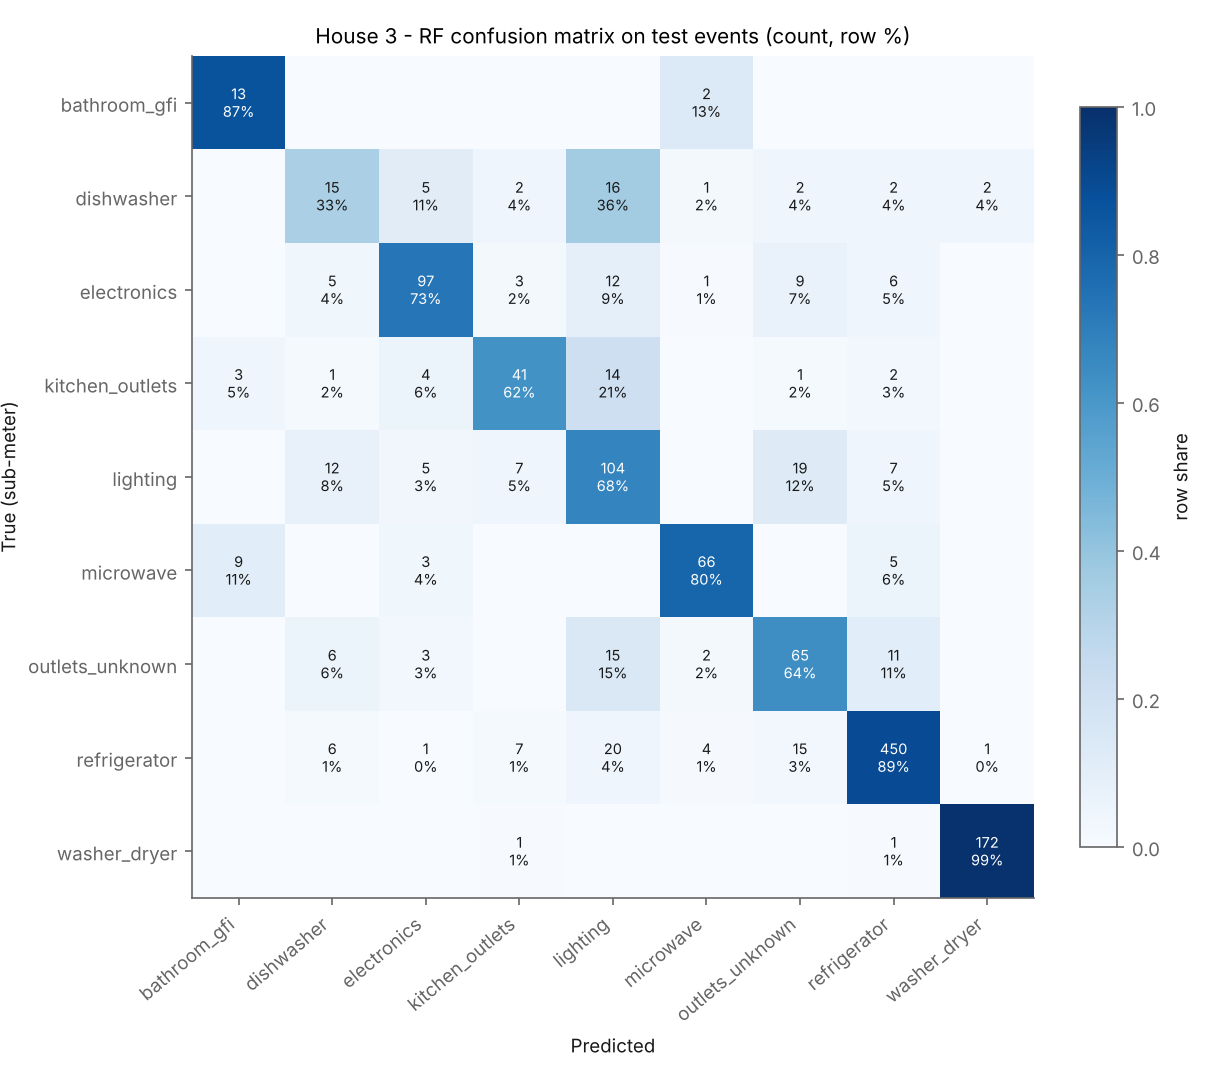

Cross-house (train on all house-1 events, test on other houses, shared classes):


,train_house,test_house,classes,n_train,n_test,accuracy,macro_f1
0,1,2,"dishwasher, kitchen_outlets, lighting, microwa...",2362,2223,0.637,0.566
1,1,3,"bathroom_gfi, dishwasher, kitchen_outlets, lig...",2720,3358,0.463,0.461


In [11]:
for h in (2, 3):
    print(f"House {h}"); print(results[h]["report_txt"])
display(Image(PLOTS / "house2_confusion.png")); display(Image(PLOTS / "house3_confusion.png"))
print("Cross-house (train on all house-1 events, test on other houses, shared classes):")
display(cross)

### 7. Leakage checks

In [12]:
lk = pd.DataFrame({h: r["leakage"] for h, r in results.items()})
display(lk)
for h, r in results.items():
    L = r["leakage"]
    assert L["no_time_overlap"] and L["no_shared_events"] and L["no_shared_gt_events"]
    assert L["gap_seconds"] >= 2 * 600 - 1
print("all leakage assertions passed")

,1,2,3
train_last_event_end,1304404613,1303957069,1306016342
test_first_event_start,1304410428,1303963213,1306017853
gap_seconds,5815,6144,1511
no_time_overlap,True,True,True
no_shared_events,True,True,True
no_shared_gt_events,True,True,True
detector_tuned_on,train period only,train period only,train period only
scaler_and_models_fit_on,train only,train only,train only
identical_feature_rows_train_test,0,0,0


all leakage assertions passed


### 8. Example events (right and wrong)

,house,kind,utc,true,pred,delta_p_w
0,1,correct,2011-05-23 01:06:54,dishwasher,dishwasher,-847.1
1,1,correct,2011-05-22 22:14:39,washer_dryer,washer_dryer,-5177.9
2,1,correct,2011-05-24 00:39:50,microwave,microwave,1538.7
3,1,wrong,2011-05-03 09:42:53,refrigerator,lighting,-79.5
4,1,wrong,2011-05-03 12:24:40,dishwasher,refrigerator,225.2
5,1,wrong,2011-05-03 11:42:55,dishwasher,kitchen_outlets,874.1
6,1,false pos.,2011-05-23 19:45:21,unmatched,NaN,39.4
7,1,missed,2011-05-24 12:14:56,washer_dryer,NaN,-79.0


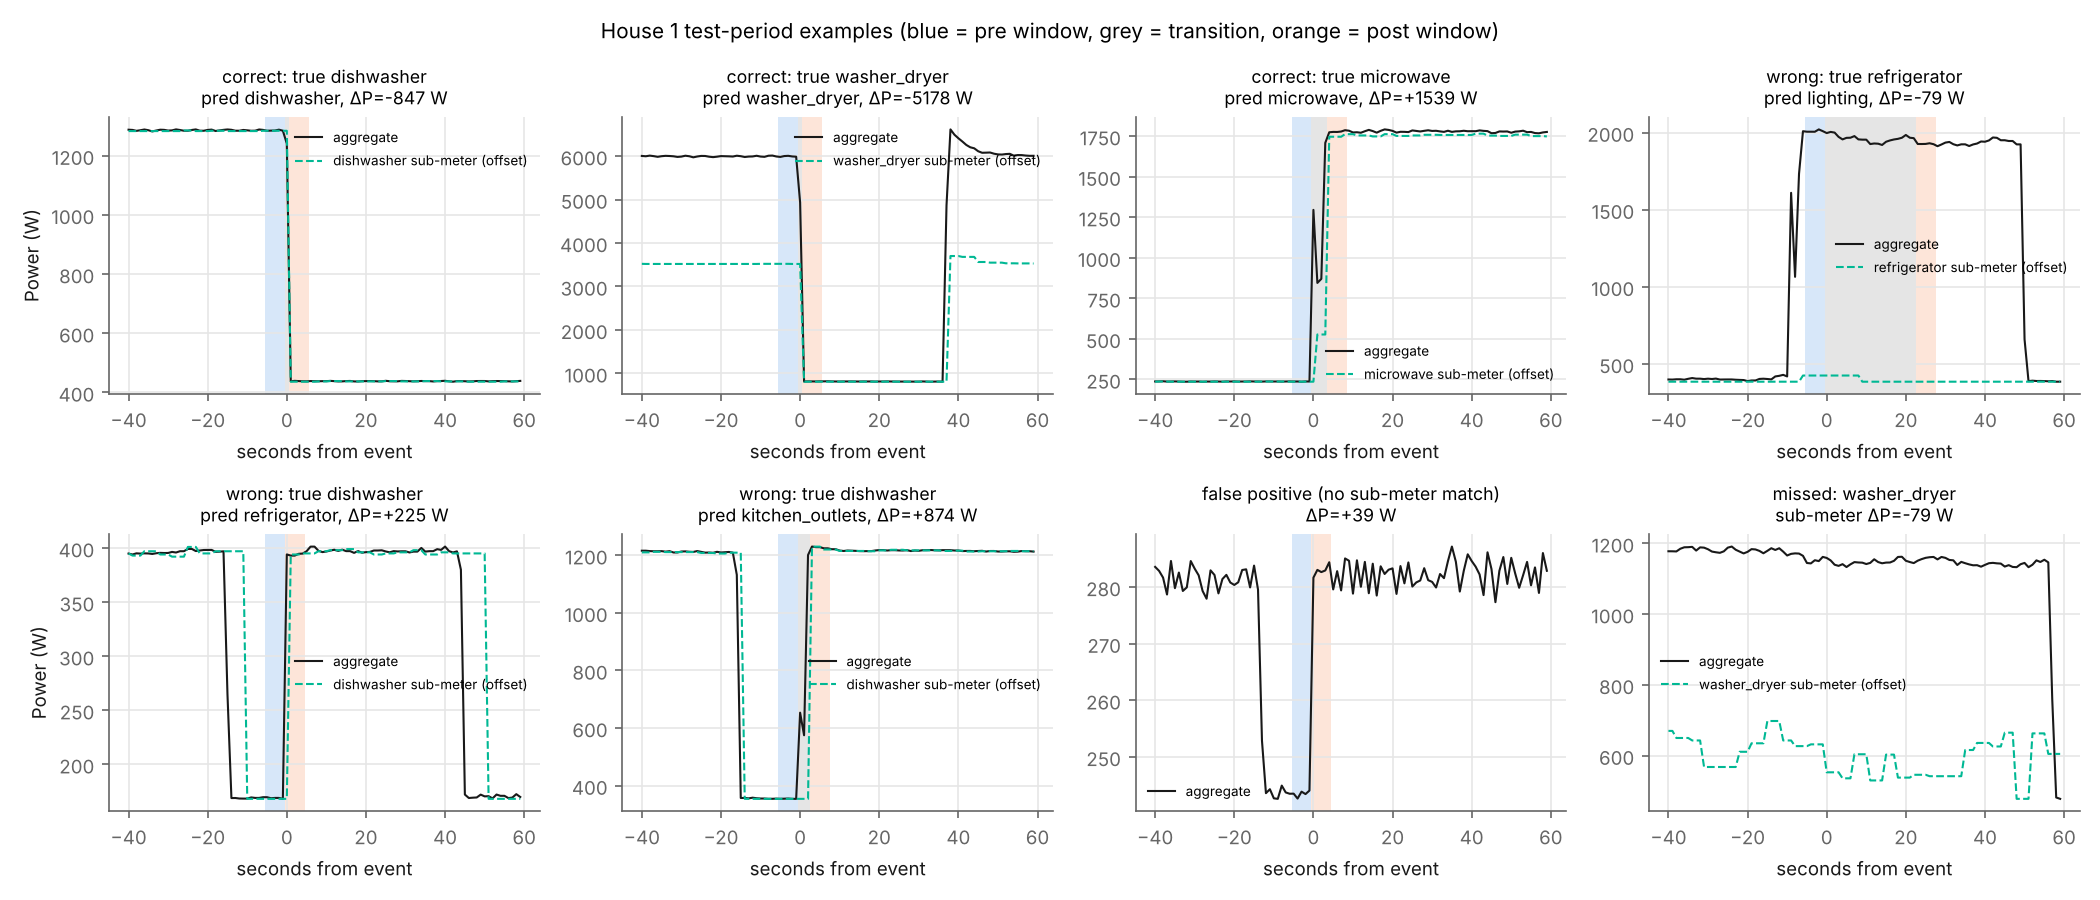

In [13]:
ex = pd.read_csv(OUT / "example_events.csv")
display(ex[ex.house == 1])
display(Image(PLOTS / "house1_examples.png"))

## 9. Findings (from the run above)

See `docs/research_log.md` for the narrative and numbers. In short:

* The detector finds every step in the synthetic test, ignores spikes, sub-threshold blips and gaps, and its
  steady windows never touch transition samples (also checked on all real events).
* On REDD, event F1 on the held-out period is ≈0.76–0.85 per house. Misses are concentrated in the washer/dryer
  (motor noise and overlapping steps) and in busy periods; part of the "false positives" are real events of
  unmetered loads (~24 % of house-1 energy is not sub-metered), so precision is a lower bound.
* On correctly detected test events, Random Forest reaches 80–96 % accuracy (macro-F1 0.71–0.90), well above
  the majority baseline. Transient features (overshoot, transition length) add 4–10 accuracy points over steady-state-only features.
* Models do **not** transfer between homes (house1→house3 macro-F1 ≈ 0.46): per-home training/calibration is required.

**Limitations:** REDD mains are apparent power, sub-meters are real power; no reactive power, voltage or
harmonics at 1 Hz; ground truth is derived from sub-meters with the same detector; mixed circuits
(outlets, lighting) are labels, not single appliances; OFF events of multi-state appliances are classified
independently (no ON-list pairing yet).